# **UMKM Success Predictor and Recommendation System: Pendekatan Explainable Machine Learning untuk Prediksi Keberhasilan dan Penyusunan Strategi Pengembangan UMKM** ##

Disusun oleh: si paling zigma
- Danella Citra Aldarena
- Maria Immaculata Dyah Hita Widowati
- Ike Maya Setya

## **Import Library**

In [ ]:
!pip install catboost

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.preprocessing import StandardScaler

# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)

# Boosting
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

## **Membaca Data**

In [ ]:
df = pd.read_csv("umkm_success.csv")
df

,Age,Education,Initial_Capital,Financial_Record_Keeping,Internet_Usage,Business_Plan,Marketing_Effort,Partnership,Parent_Business_Experience,Industry_Experience,Owner_Gender,Professional_Advice,Success
0,60,3,0,0,0,0,5,1,1,5,1,3,0
1,51,4,1,1,0,0,7,1,1,4,1,7,0
2,21,1,0,1,1,0,7,0,0,19,1,2,0
3,20,1,0,1,1,1,5,1,0,1,1,2,0
4,35,1,1,1,0,1,3,0,1,3,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
245,36,3,1,1,0,1,5,0,0,2,1,4,0
246,44,2,1,0,0,1,3,1,1,6,0,1,0
247,38,2,0,0,0,1,2,1,1,10,0,5,0
248,26,5,0,1,0,1,5,1,1,12,0,2,0


## **Explanatory Data Analysis**

### **Distribusi Status Keberhasilan UMKM**

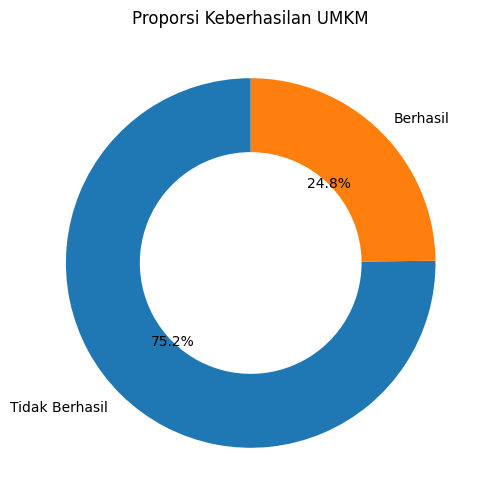

In [ ]:
success_count = df["Success"].value_counts()

plt.figure(figsize=(6,6))
plt.pie(
    success_count,
    labels=["Tidak Berhasil","Berhasil"],
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops=dict(width=0.4)
)
plt.title("Proporsi Keberhasilan UMKM")
plt.show()

### **Distribusi Usia Pemilik UMKM**

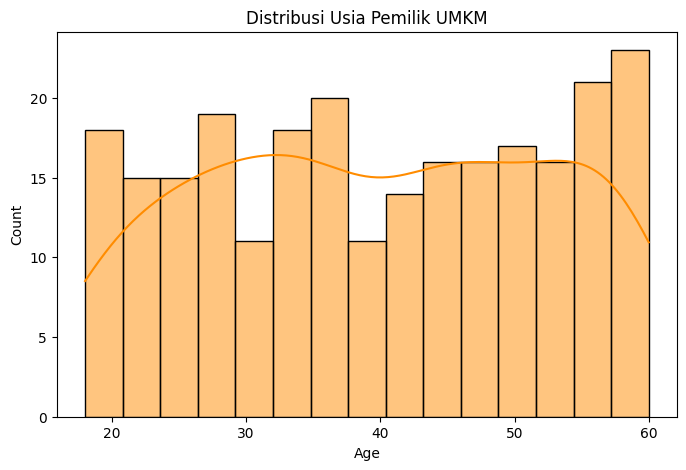

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(
    df["Age"],
    kde=True,
    color="darkorange",
    bins=15
)
plt.title("Distribusi Usia Pemilik UMKM")
plt.show()

### **Distribusi Pengalaman Industri berdasarkan Status Keberhasilan**

/tmp/ipykernel_1462/2793010480.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


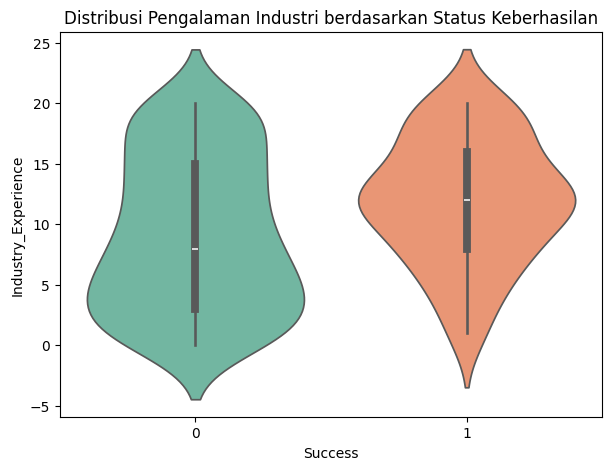

In [ ]:
plt.figure(figsize=(7,5))
sns.violinplot(
    x="Success",
    y="Industry_Experience",
    data=df,
    palette="Set2"
)
plt.title(
    "Distribusi Pengalaman Industri berdasarkan Status Keberhasilan"
)
plt.show()

### **Distribusi Upaya Pemasaran berdasarkan Status Keberhasilan**

/tmp/ipykernel_1462/1601505341.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(


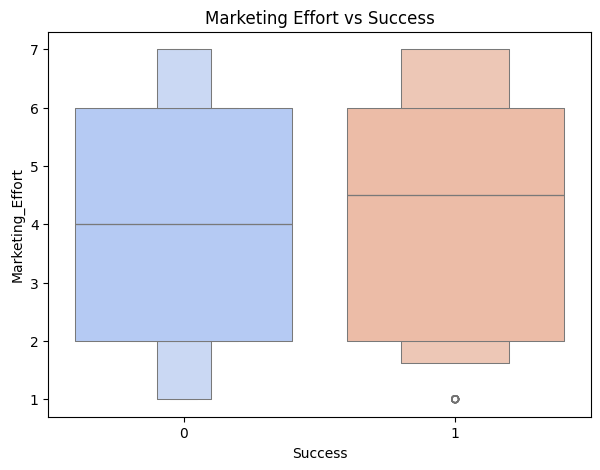

In [ ]:
plt.figure(figsize=(7,5))
sns.boxenplot(
    x="Success",
    y="Marketing_Effort",
    data=df,
    palette="coolwarm"
)
plt.title(
    "Marketing Effort vs Success"
)
plt.show()

### **Persentase Tingkat Keberhasilan berdasarkan Pendidikan**

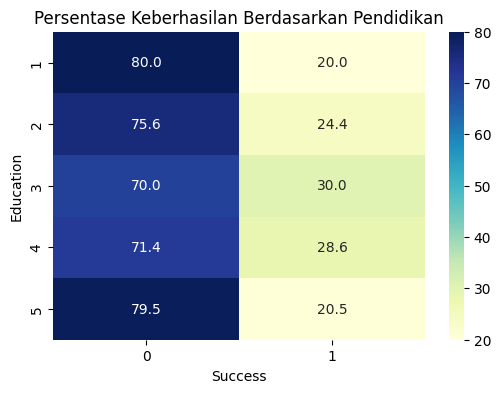

In [ ]:
education_table = pd.crosstab(
    df["Education"],
    df["Success"],
    normalize="index"
) * 100

plt.figure(figsize=(6,4))

sns.heatmap(
    education_table,
    annot=True,
    cmap="YlGnBu",
    fmt=".1f"
)

plt.title(
    "Persentase Keberhasilan Berdasarkan Pendidikan"
)

plt.show()

### **Persentase Tingkat Keberhasilan berdasarkan Penggunaan Internet**

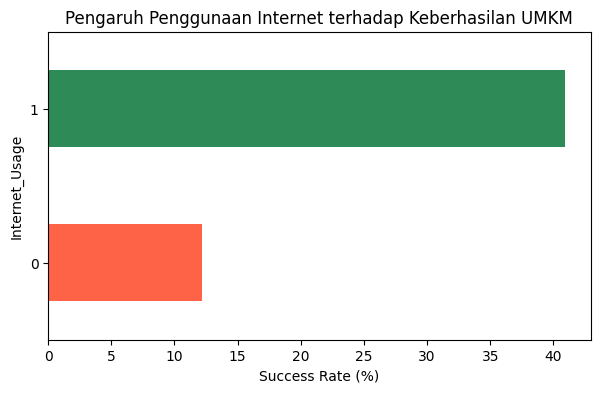

In [ ]:
internet_success = (

    pd.crosstab(
        df["Internet_Usage"],
        df["Success"],
        normalize="index"
    )[1]

    *100
)

internet_success.plot(
    kind="barh",
    color=["tomato","seagreen"],
    figsize=(7,4)
)

plt.xlabel("Success Rate (%)")

plt.title(
    "Pengaruh Penggunaan Internet terhadap Keberhasilan UMKM"
)

plt.show()

### **Distribusi Pencatatan Keuangan terhadap Keberhasilan UMKM**

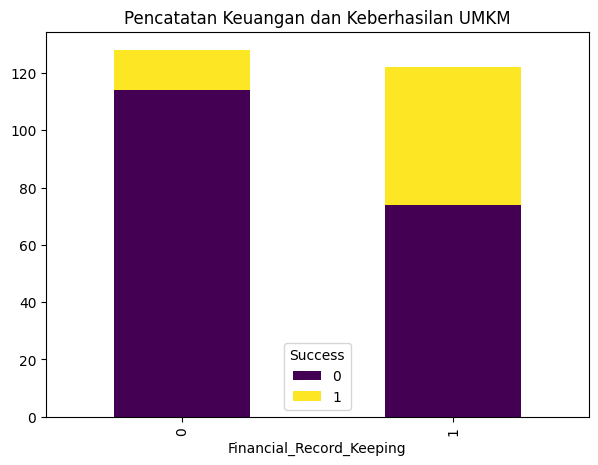

In [ ]:
table = pd.crosstab(
    df["Financial_Record_Keeping"],
    df["Success"]
)

table.plot(
    kind="bar",
    stacked=True,
    colormap="viridis",
    figsize=(7,5)
)

plt.title(
    "Pencatatan Keuangan dan Keberhasilan UMKM"
)

plt.show()

### **Persentase Keberhasilan terhadap Keberhasilan UMKM**

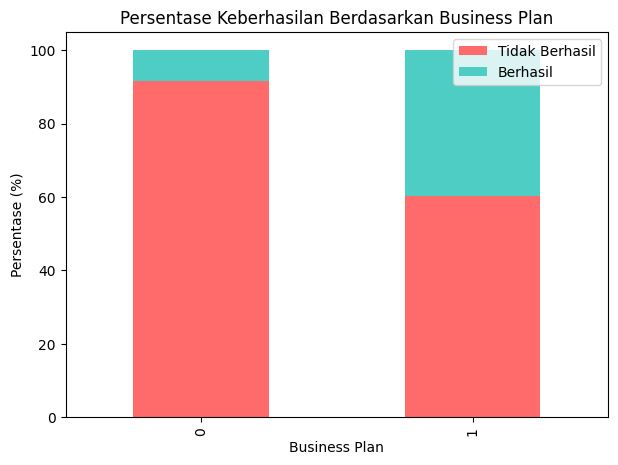

In [ ]:
business_plan = pd.crosstab(
    df["Business_Plan"],
    df["Success"],
    normalize="index"
) * 100

business_plan.plot(
    kind="bar",
    stacked=True,
    figsize=(7,5),
    color=["#FF6B6B", "#4ECDC4"]
)

plt.ylabel("Persentase (%)")
plt.xlabel("Business Plan")
plt.title("Persentase Keberhasilan Berdasarkan Business Plan")

plt.legend(
    ["Tidak Berhasil", "Berhasil"]
)

plt.show()

### **Matriks Korelasi Variabel Penelitian**

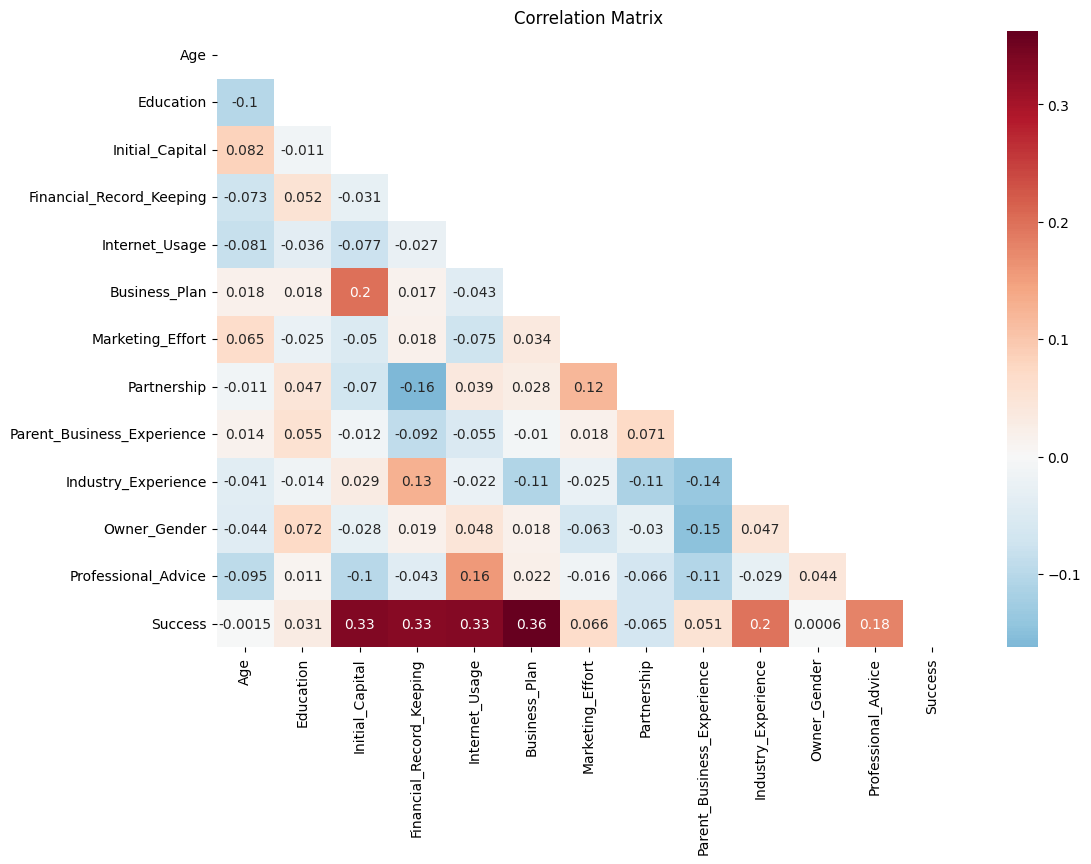

In [ ]:
corr = df.corr()

mask = np.triu(
    np.ones_like(corr)
)

plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    cmap="RdBu_r",
    center=0
)

plt.title(
    "Correlation Matrix"
)

plt.show()

## **Preprocessing Data**

### **Cek Tipe Data**

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         250 non-null    int64
 1   Education                   250 non-null    int64
 2   Initial_Capital             250 non-null    int64
 3   Financial_Record_Keeping    250 non-null    int64
 4   Internet_Usage              250 non-null    int64
 5   Business_Plan               250 non-null    int64
 6   Marketing_Effort            250 non-null    int64
 7   Partnership                 250 non-null    int64
 8   Parent_Business_Experience  250 non-null    int64
 9   Industry_Experience         250 non-null    int64
 10  Owner_Gender                250 non-null    int64
 11  Professional_Advice         250 non-null    int64
 12  Success                     250 non-null    int64
dtypes: int64(13)
memory usage: 25.5 KB
None


### **Cek Missing Value**

In [ ]:
missing = pd.DataFrame({
    "Missing Value": df.isnull().sum(),
    "Persentase (%)": round(df.isnull().mean()*100,2)
})

print(missing)

                            Missing Value  Persentase (%)
Age                                     0             0.0
Education                               0             0.0
Initial_Capital                         0             0.0
Financial_Record_Keeping                0             0.0
Internet_Usage                          0             0.0
Business_Plan                           0             0.0
Marketing_Effort                        0             0.0
Partnership                             0             0.0
Parent_Business_Experience              0             0.0
Industry_Experience                     0             0.0
Owner_Gender                            0             0.0
Professional_Advice                     0             0.0
Success                                 0             0.0


### **Cek Data Duplikat**

In [ ]:
print("Jumlah data duplikat:",
      df.duplicated().sum())

Jumlah data duplikat: 0


### **Memisahkan  Variabel Prediktor dan Target**

In [ ]:
X = df.drop("Success", axis=1)
y = df["Success"]

### **Pembagian Data Training dan Testing**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### **Standardisasi Data**

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## **Pembangunan Model Machine Learning**

In [ ]:
models = {
    "Logistic Regression":
        LogisticRegression(max_iter=1000),
    "Decision Tree":
        DecisionTreeClassifier(random_state=42),
    "Random Forest":
        RandomForestClassifier(random_state=42),
    "Extra Trees":
        ExtraTreesClassifier(random_state=42),
    "Gradient Boosting":
        GradientBoostingClassifier(random_state=42),
    "AdaBoost":
        AdaBoostClassifier(random_state=42),
    "KNN":
        KNeighborsClassifier(),
    "Naive Bayes":
        GaussianNB(),
    "SVM":
        SVC(probability=True),
    "XGBoost":
        XGBClassifier(
            eval_metric='logloss',
            random_state=42
        ),
    "LightGBM":
        LGBMClassifier(random_state=42),
    "CatBoost":
        CatBoostClassifier(
            verbose=0,
            random_state=42
        )
}

## **Evaluasi dan Perbandingan Model**

In [ ]:
results = []

for name, model in models.items():
    # Model yang perlu scaling
    if name in [
        "Logistic Regression",
        "KNN",
        "SVM"
    ]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:,1]

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:,1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
results_df.sort_values(
    by="ROC AUC",
    ascending=False
)

[LightGBM] [Info] Number of positive: 50, number of negative: 150
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001541 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 99
[LightGBM] [Info] Number of data points in the train set: 200, number of used features: 12
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.250000 -> initscore=-1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best g

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.92,0.785714,0.916667,0.846154,0.991228
5,AdaBoost,0.96,0.916667,0.916667,0.916667,0.984649
9,XGBoost,0.92,0.833333,0.833333,0.833333,0.971491
10,LightGBM,0.88,0.800000,0.666667,0.727273,0.969298
8,SVM,0.90,0.818182,0.750000,0.782609,0.964912
11,CatBoost,0.92,0.833333,0.833333,0.833333,0.953947
7,Naive Bayes,0.86,0.777778,0.583333,0.666667,0.940789
3,Extra Trees,0.88,0.800000,0.666667,0.727273,0.935307
4,Gradient Boosting,0.84,0.700000,0.583333,0.636364,0.921053
2,Random Forest,0.80,0.666667,0.333333,0.444444,0.911184


## **Mencoba model Deep Learning**

In [ ]:
ann = Sequential()

ann.add(Dense(
    64,
    activation='relu',
    input_shape=(X_train_scaled.shape[1],)
))

ann.add(Dropout(0.2))
ann.add(Dense(
    32,
    activation='relu'
))

ann.add(Dropout(0.2))
ann.add(Dense(
    16,
    activation='relu'
))

ann.add(Dense(
    1,
    activation='sigmoid'
))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
ann.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = ann.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 188ms/step - accuracy: 0.7188 - loss: 0.6185 - val_accuracy: 0.7000 - val_loss: 0.6489
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.7500 - loss: 0.5805 - val_accuracy: 0.7000 - val_loss: 0.6293
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.7688 - loss: 0.5591 - val_accuracy: 0.7000 - val_loss: 0.6117
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.7688 - loss: 0.5373 - val_accuracy: 0.7000 - val_loss: 0.5950
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 76ms/step - accuracy: 0.7688 - loss: 0.4939 - val_accuracy: 0.7000 - val_loss: 0.5803
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.7750 - loss: 0.4764 - val_accuracy: 0.7000 - val_loss: 0.5678
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.7750 - loss: 0.4624 - val_accuracy: 0.7250 - val_loss: 0.5555
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.7812 - loss: 0.4543 - val_accuracy: 0.7250 - val_l

In [ ]:
y_prob_ann = ann.predict(X_test_scaled)
y_pred_ann = (
    y_prob_ann > 0.5
).astype(int)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step


In [ ]:
ann_result = pd.DataFrame({
    "Model":["ANN"],
    "Accuracy":[
        accuracy_score(y_test,y_pred_ann)
    ],
    "Precision":[
        precision_score(y_test,y_pred_ann)
    ],
    "Recall":[
        recall_score(y_test,y_pred_ann)
    ],
    "F1 Score":[
        f1_score(y_test,y_pred_ann)
    ],
    "ROC AUC":[
        roc_auc_score(y_test,y_prob_ann)
    ]
})

ann_result

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,ANN,0.9,0.818182,0.75,0.782609,0.97807


## **Pemilihan Model Terbaik**

In [ ]:
final_results = pd.concat(
    [results_df, ann_result],
    ignore_index=True
)

final_results.sort_values(
    by="ROC AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.92,0.785714,0.916667,0.846154,0.991228
5,AdaBoost,0.96,0.916667,0.916667,0.916667,0.984649
12,ANN,0.90,0.818182,0.750000,0.782609,0.978070
9,XGBoost,0.92,0.833333,0.833333,0.833333,0.971491
10,LightGBM,0.88,0.800000,0.666667,0.727273,0.969298
8,SVM,0.90,0.818182,0.750000,0.782609,0.964912
11,CatBoost,0.92,0.833333,0.833333,0.833333,0.953947
7,Naive Bayes,0.86,0.777778,0.583333,0.666667,0.940789
3,Extra Trees,0.88,0.800000,0.666667,0.727273,0.935307
4,Gradient Boosting,0.84,0.700000,0.583333,0.636364,0.921053


## **Cross Validation**

**mencoba dengan 10-Fold Cross Validation untuk mengecek apakah model benar-benar bagus pada banyak pembagian data yang berbeda**

In [ ]:
from sklearn.model_selection import cross_val_score
import pandas as pd

cv_results = []
for name, model in models.items():
    print(f"Sedang menjalankan: {name}")
    try:
        scores = cross_val_score(
            model,
            X,
            y,
            cv=10,
            scoring='f1'
        )
        cv_results.append({
            "Model": name,
            "Mean F1": scores.mean(),
            "Std F1": scores.std(),
            "Min F1": scores.min(),
            "Max F1": scores.max()
        })

        print(f"Mean F1 = {scores.mean():.4f}")

    except Exception as e:
        print(f"{name} gagal:")
        print(e)

cv_results = pd.DataFrame(cv_results)
cv_results = cv_results.sort_values(
    by="Mean F1",
    ascending=False
)

print("\n===== HASIL CROSS VALIDATION =====")
print(cv_results)

Sedang menjalankan: Logistic Regression
Mean F1 = 0.8648
Sedang menjalankan: Decision Tree
Mean F1 = 0.6875
Sedang menjalankan: Random Forest
Mean F1 = 0.6780
Sedang menjalankan: Extra Trees
Mean F1 = 0.7532
Sedang menjalankan: Gradient Boosting
Mean F1 = 0.8276
Sedang menjalankan: AdaBoost
Mean F1 = 0.9479
Sedang menjalankan: KNN
Mean F1 = 0.2560
Sedang menjalankan: Naive Bayes
Mean F1 = 0.6113
Sedang menjalankan: SVM
Mean F1 = 0.0000
Sedang menjalankan: XGBoost
Mean F1 = 0.8453
Sedang menjalankan: LightGBM
[LightGBM] [Info] Number of positive: 56, number of negative: 169
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000137 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 99
[LightGBM] [Info] Number of data points in the train set: 225, number of used features: 12
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.248889 -> initscore=-1.104547
[LightGBM] [Info] Start training from score -1.104547
[

cross validation bukan untuk mengganti accuracy/F1 dari data test set, tetapi untuk memvalidasi bahwa hasil tersebut stabil

## **Hyperparameter Tuning**

untuk mencari apakah model bisa dibuat lebih optimal

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

In [ ]:
param_grid = {
    'n_estimators': [50, 100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1],
    'estimator': [
        DecisionTreeClassifier(max_depth=1),
        DecisionTreeClassifier(max_depth=2),
        DecisionTreeClassifier(max_depth=3)
    ]
}

In [ ]:
grid_search = GridSearchCV(
    estimator=AdaBoostClassifier(
        random_state=42
    ),
    param_grid=param_grid,
    scoring='f1',
    cv=10,
    n_jobs=-1
)

In [ ]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=AdaBoostClassifier(random_state=42), n_jobs=-1,
             param_grid={'estimator': [DecisionTreeClassifier(max_depth=1),
                                       DecisionTreeClassifier(max_depth=2),
                                       DecisionTreeClassifier(max_depth=3)],
                         'learning_rate': [0.01, 0.05, 0.1, 0.5, 1],
                         'n_estimators': [50, 100, 200, 300]},
             scoring='f1')

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1:")
print(grid_search.best_score_)

Best Parameters:
{'estimator': DecisionTreeClassifier(max_depth=1), 'learning_rate': 1, 'n_estimators': 100}

Best CV F1:
0.9123232323232322


In [ ]:
best_model = grid_search.best_estimator_

In [ ]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:,1]

In [ ]:
print("Accuracy:",
      accuracy_score(y_test,y_pred))
print("Precision:",
      precision_score(y_test,y_pred))
print("Recall:",
      recall_score(y_test,y_pred))
print("F1:",
      f1_score(y_test,y_pred))
print("ROC AUC:",
      roc_auc_score(y_test,y_prob))

Accuracy: 0.94
Precision: 0.8
Recall: 1.0
F1: 0.8888888888888888
ROC AUC: 1.0


Hasil hyperparameter tuning menunjukkan bahwa optimasi parameter tidak meningkatkan performa model. Nilai accuracy yang diperoleh setelah tuning justru lebih rendah dibandingkan model dengan parameter default. Oleh karena itu, model dengan parameter default dipertahankan sebagai model terbaik dan digunakan pada tahap analisis selanjutnya.

## **Model Terbaik**

**AdaBoost**

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

final_model = AdaBoostClassifier(
    random_state=42
)

final_model.fit(
    X_train,
    y_train
)

AdaBoostClassifier(random_state=42)

| Metrik    |  Nilai |
| --------- | -----: |
| Accuracy  |   0.96 |
| Precision | 0.9167 |
| Recall    | 0.9167 |
| F1-Score  | 0.9167 |
| ROC-AUC   | 0.9846 |

| Metrik  |  Nilai |
| ------- | -----: |
| Mean F1 | 0.9479 |
| Std F1  | 0.0725 |
| Min F1  | 0.8000 |
| Max F1  | 1.0000 |


Berdasarkan hasil evaluasi, model AdaBoost menunjukkan performa yang sangat baik dalam memprediksi keberhasilan UMKM. Pada data pengujian, model menghasilkan Accuracy sebesar 96%, Precision sebesar 91,67%, Recall sebesar 91,67%, F1-Score sebesar 91,67%, dan ROC-AUC sebesar 98,46%. Selain itu, hasil 10-Fold Cross Validation menunjukkan nilai rata-rata F1-Score sebesar 94,79% dengan standar deviasi 7,25%, yang mengindikasikan bahwa model memiliki performa yang stabil dan mampu melakukan generalisasi dengan baik pada berbagai subset data. Berdasarkan hasil tersebut, AdaBoost dipilih sebagai model terbaik.

## **Feature Importance**

In [ ]:
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance":
        final_model.feature_importances_

})
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
5,Business_Plan,0.198325
9,Industry_Experience,0.184002
4,Internet_Usage,0.160060
2,Initial_Capital,0.126183
3,Financial_Record_Keeping,0.115736
11,Professional_Advice,0.070061
6,Marketing_Effort,0.043016
8,Parent_Business_Experience,0.039863
1,Education,0.031411
0,Age,0.031343


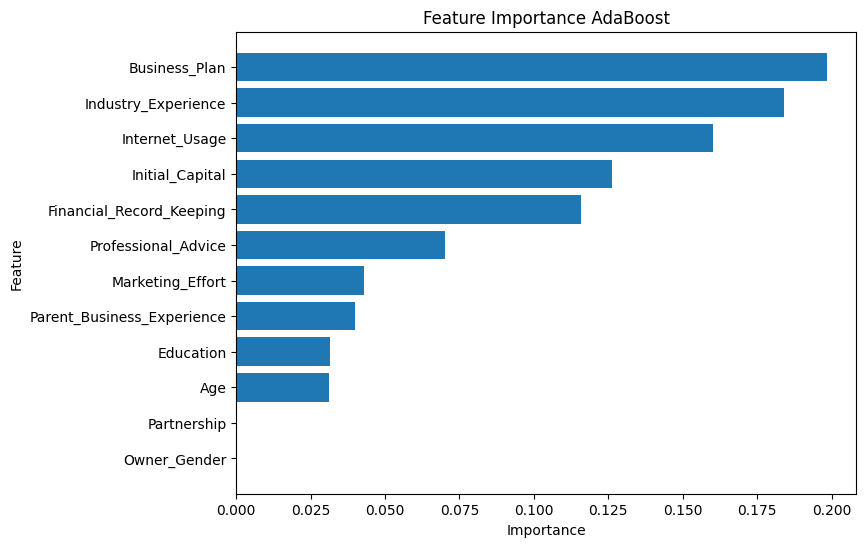

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance AdaBoost")

plt.show()

In [ ]:
top5 = importance_df.head(5)

print(top5)

                    Feature  Importance
5             Business_Plan    0.198325
9       Industry_Experience    0.184002
4            Internet_Usage    0.160060
2           Initial_Capital    0.126183
3  Financial_Record_Keeping    0.115736


## **SHAP Analysis**

In [ ]:
!pip install shap

In [ ]:
import shap

In [ ]:
explainer = shap.Explainer(
    final_model.predict,
    X_train
)

In [ ]:
shap_values = explainer(
    X_test
)

PermutationExplainer explainer: 51it [00:51,  1.03s/it]


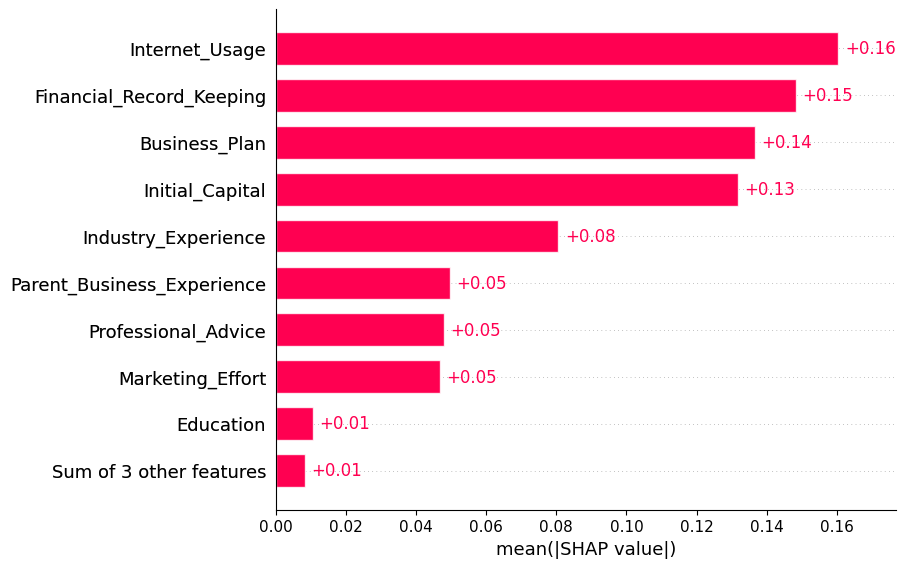

In [ ]:
shap.plots.bar(
    shap_values
)

Berbeda dengan Feature Importance yang mengukur kontribusi variabel terhadap struktur model, SHAP mengukur besarnya pengaruh variabel terhadap perubahan prediksi. Hasil SHAP menunjukkan bahwa Internet Usage memiliki dampak terbesar terhadap peluang keberhasilan UMKM, diikuti oleh Financial Record Keeping dan Business Plan.

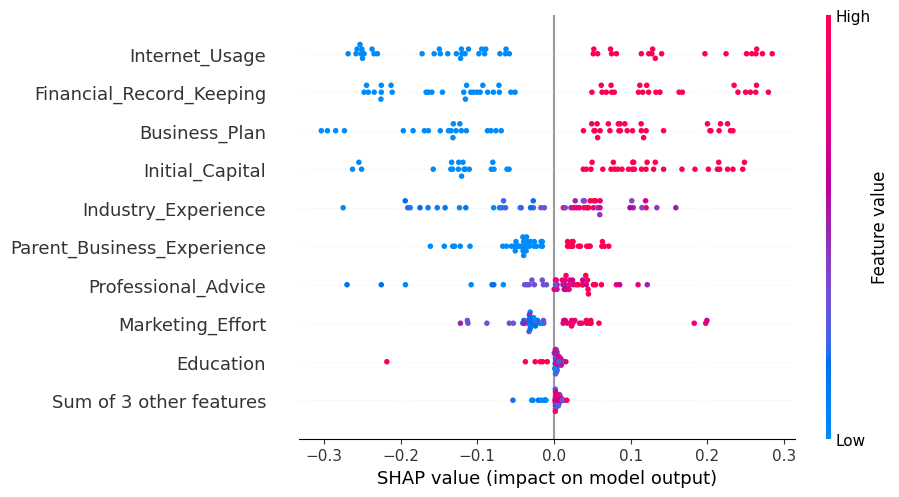

In [ ]:
shap.plots.beeswarm(
    shap_values
)

Feature Importance menunjukkan bahwa Business Plan dan Industry Experience merupakan variabel yang paling sering digunakan oleh model dalam proses klasifikasi. Namun, SHAP menunjukkan bahwa Internet Usage dan Financial Record Keeping memberikan dampak perubahan prediksi yang lebih besar terhadap peluang keberhasilan UMKM. Hal ini mengindikasikan bahwa digitalisasi usaha dan pengelolaan keuangan merupakan faktor yang paling efektif untuk meningkatkan peluang keberhasilan UMKM.

## **Risk Scoring**

In [ ]:
y_prob = final_model.predict_proba(
    X_test
)[:,1]

In [ ]:
risk_df = X_test.copy()
risk_df["Actual"] = y_test.values
risk_df["Probability_Success"] = y_prob

In [ ]:
def risk_category(prob):
    if prob >= 0.80:
        return "Sangat Berpotensi"
    elif prob >= 0.60:
        return "Potensial"
    elif prob >= 0.40:
        return "Perlu Pendampingan"
    else:
        return "Risiko Tinggi"

In [ ]:
risk_df["Risk_Category"] = (
    risk_df["Probability_Success"]
    .apply(risk_category)
)

In [ ]:
risk_df[
    [
        "Probability_Success",
        "Risk_Category"
    ]
].head()

,Probability_Success,Risk_Category
12,0.533619,Perlu Pendampingan
117,0.271973,Risiko Tinggi
61,0.192090,Risiko Tinggi
243,0.426929,Perlu Pendampingan
139,0.353128,Risiko Tinggi


In [ ]:
risk_df["Risk_Category"].value_counts()

,count
Risk_Category,
Perlu Pendampingan,24
Risiko Tinggi,23
Potensial,3


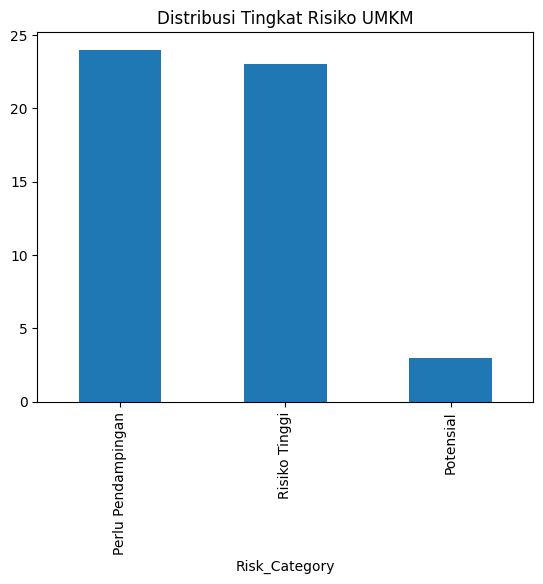

In [ ]:
risk_df["Risk_Category"].value_counts().plot(
    kind="bar"
)
plt.title("Distribusi Tingkat Risiko UMKM")
plt.show()

## **Rekomendasi Pengembangan UMKM**

In [ ]:
shap_df = pd.DataFrame(
    shap_values.values,
    columns=X_test.columns
)

In [ ]:
risk_df = risk_df.reset_index(drop=True)
shap_df = shap_df.reset_index(drop=True)

In [ ]:
recommendation_dict = {
    "Internet_Usage":
        "Mulai menggunakan digital marketing",
    "Financial_Record_Keeping":
        "Perbaiki pencatatan keuangan",
    "Business_Plan":
        "Susun business plan",
    "Initial_Capital":
        "Perkuat akses pembiayaan atau modal usaha",
    "Industry_Experience":
        "Ikuti pelatihan dan mentoring industri",
    "Professional_Advice":
        "Perbanyak konsultasi bisnis",
    "Marketing_Effort":
        "Tingkatkan aktivitas pemasaran",
    "Parent_Business_Experience":
        "Perluas jaringan dan belajar dari pelaku usaha berpengalaman",
    "Education":
        "Ikuti pelatihan kewirausahaan",
    "Age":
        "Perkuat pengembangan kapasitas usaha"
}

In [ ]:
def recommendation_system(shap_row):
    threshold = -0.05
    negative_features = (
        shap_row[
            shap_row < threshold
        ]
        .sort_values()
    )

    main_issue = list(
        negative_features.index)
    recommendation = []

    for feature in main_issue:
        if feature in recommendation_dict:
            recommendation.append(
                recommendation_dict[feature])

    if len(main_issue) == 0:
        return pd.Series({
            "Main_Issue":
                "Tidak ada isu utama",
            "Recommendation":
                "Pertahankan strategi bisnis saat ini"
        })

    return pd.Series({
        "Main_Issue":
            ", ".join(main_issue),
        "Recommendation":
            "; ".join(recommendation)

    })

In [ ]:
recommendation_result = (
    shap_df.apply(
        recommendation_system,
        axis=1)
)

In [ ]:
risk_df = pd.concat([risk_df, recommendation_result], axis=1)

In [ ]:
risk_df[[
        "Probability_Success",
        "Risk_Category",
        "Main_Issue",
        "Recommendation"]]

,Probability_Success,Risk_Category,Main_Issue,Recommendation
0,0.533619,Perlu Pendampingan,"Internet_Usage, Professional_Advice, Parent_Bu...",Mulai menggunakan digital marketing; Perbanyak...
1,0.271973,Risiko Tinggi,"Internet_Usage, Initial_Capital, Financial_Rec...",Mulai menggunakan digital marketing; Perkuat a...
2,0.192090,Risiko Tinggi,"Business_Plan, Internet_Usage, Initial_Capital...",Susun business plan; Mulai menggunakan digital...
3,0.426929,Perlu Pendampingan,"Internet_Usage, Financial_Record_Keeping",Mulai menggunakan digital marketing; Perbaiki ...
4,0.353128,Risiko Tinggi,"Industry_Experience, Initial_Capital, Financia...",Ikuti pelatihan dan mentoring industri; Perkua...
5,0.463983,Perlu Pendampingan,"Internet_Usage, Financial_Record_Keeping, Pare...",Mulai menggunakan digital marketing; Perbaiki ...
6,0.303479,Risiko Tinggi,"Business_Plan, Industry_Experience, Internet_U...",Susun business plan; Ikuti pelatihan dan mento...
7,0.378423,Risiko Tinggi,"Business_Plan, Initial_Capital, Age",Susun business plan; Perkuat akses pembiayaan ...
8,0.440011,Perlu Pendampingan,"Internet_Usage, Financial_Record_Keeping",Mulai menggunakan digital marketing; Perbaiki ...
9,0.212766,Risiko Tinggi,"Initial_Capital, Business_Plan, Internet_Usage...",Perkuat akses pembiayaan atau modal usaha; Sus...


In [ ]:
from collections import Counter

all_issue = []

for x in risk_df["Main_Issue"]:
    if x != "Tidak ada isu utama":
        all_issue.extend(
            [i.strip() for i in x.split(",")]
        )

issue_freq = pd.DataFrame(
    Counter(all_issue).items(),
    columns=["Main_Issue","Frekuensi"]
)

issue_freq = issue_freq.sort_values(
    "Frekuensi",
    ascending=False
)

print(issue_freq)

                   Main_Issue  Frekuensi
0              Internet_Usage         30
4    Financial_Record_Keeping         27
6               Business_Plan         21
3             Initial_Capital         19
5         Industry_Experience         15
2  Parent_Business_Experience         12
1         Professional_Advice          7
8            Marketing_Effort          6
7                         Age          1
9                   Education          1


In [ ]:
all_rec = []

for x in risk_df["Recommendation"]:
    if x != "Pertahankan strategi bisnis saat ini":

        all_rec.extend(
            [i.strip() for i in x.split(";")]
        )

rec_freq = pd.DataFrame(
    Counter(all_rec).items(),
    columns=["Recommendation","Frekuensi"]
)

rec_freq = rec_freq.sort_values(
    "Frekuensi",
    ascending=False
)

print(rec_freq)

                                      Recommendation  Frekuensi
0                Mulai menggunakan digital marketing         30
4                       Perbaiki pencatatan keuangan         27
6                                Susun business plan         21
3          Perkuat akses pembiayaan atau modal usaha         19
5             Ikuti pelatihan dan mentoring industri         15
2  Perluas jaringan dan belajar dari pelaku usaha...         12
1                        Perbanyak konsultasi bisnis          7
8                     Tingkatkan aktivitas pemasaran          6
7               Perkuat pengembangan kapasitas usaha          1
9                      Ikuti pelatihan kewirausahaan          1


In [ ]:
risk_df[
    [
        "Probability_Success",
        "Risk_Category",
        "Main_Issue",
        "Recommendation"
    ]
].head(10)

,Probability_Success,Risk_Category,Main_Issue,Recommendation
0,0.533619,Perlu Pendampingan,"Internet_Usage, Professional_Advice, Parent_Bu...",Mulai menggunakan digital marketing; Perbanyak...
1,0.271973,Risiko Tinggi,"Internet_Usage, Initial_Capital, Financial_Rec...",Mulai menggunakan digital marketing; Perkuat a...
2,0.192090,Risiko Tinggi,"Business_Plan, Internet_Usage, Initial_Capital...",Susun business plan; Mulai menggunakan digital...
3,0.426929,Perlu Pendampingan,"Internet_Usage, Financial_Record_Keeping",Mulai menggunakan digital marketing; Perbaiki ...
4,0.353128,Risiko Tinggi,"Industry_Experience, Initial_Capital, Financia...",Ikuti pelatihan dan mentoring industri; Perkua...
5,0.463983,Perlu Pendampingan,"Internet_Usage, Financial_Record_Keeping, Pare...",Mulai menggunakan digital marketing; Perbaiki ...
6,0.303479,Risiko Tinggi,"Business_Plan, Industry_Experience, Internet_U...",Susun business plan; Ikuti pelatihan dan mento...
7,0.378423,Risiko Tinggi,"Business_Plan, Initial_Capital, Age",Susun business plan; Perkuat akses pembiayaan ...
8,0.440011,Perlu Pendampingan,"Internet_Usage, Financial_Record_Keeping",Mulai menggunakan digital marketing; Perbaiki ...
9,0.212766,Risiko Tinggi,"Initial_Capital, Business_Plan, Internet_Usage...",Perkuat akses pembiayaan atau modal usaha; Sus...


## **Synthetic Policy Evaluation**

Dari feature importance yang udah didapatkan tadi, berikut merupakan kebijakan yang relevan:

**1. Program A: Business Incubation**
  Meningkatkan:
- Business_Plan
- Financial_Record_Keeping

**2. Program B: Digital Transformation**
  Meningkatkan:
- Internet_Usage

**3. Program C: Capital Assistance**
  Meningkatkan:
- Initial_Capital

**4. Program D: Integrated UMKM Development**
  Meningkatkan:
- Business_Plan
- Internet_Usage
- Financial_Record_Keeping

In [ ]:
df.head()

,Age,Education,Initial_Capital,Financial_Record_Keeping,Internet_Usage,Business_Plan,Marketing_Effort,Partnership,Parent_Business_Experience,Industry_Experience,Owner_Gender,Professional_Advice,Success
0,60,3,0,0,0,0,5,1,1,5,1,3,0
1,51,4,1,1,0,0,7,1,1,4,1,7,0
2,21,1,0,1,1,0,7,0,0,19,1,2,0
3,20,1,0,1,1,1,5,1,0,1,1,2,0
4,35,1,1,1,0,1,3,0,1,3,0,1,0


In [ ]:
X = df.drop('Success', axis=1)
y = df['Success']

In [ ]:
baseline_prob = final_model.predict_proba(X)[:,1]

baseline_success_rate = np.mean(
    baseline_prob > 0.5
)

print(f"Baseline Success Rate : {baseline_success_rate:.4f}")

Baseline Success Rate : 0.2480


### **Program A — Business Incubation**

Asumsi:

Program berhasil membuat UMKM yang belum punya business plan menjadi punya business plan dan pencatatan keuangan menjadi baik.

#### Asumsi mengjangkau 30% UMKM

In [ ]:
# asumsi hanya menjangkau 30% UMKM
scenario_A = X.copy()

target1 = scenario_A[
    scenario_A['Business_Plan']==0
].sample(
    frac=0.3,
    random_state=42
).index

scenario_A.loc[target1,'Business_Plan']=1

target2 = scenario_A[
    scenario_A['Financial_Record_Keeping']==0
].sample(
    frac=0.3,
    random_state=42
).index

scenario_A.loc[target2,'Financial_Record_Keeping']=1

In [ ]:
prob_A30 = final_model.predict_proba(
    scenario_A
)[:,1]

success_A30 = np.mean(
    prob_A30 > 0.5
)

print(success_A30)

0.348


#### Asumsi menjangkau 60% UMKM

In [ ]:
# asumsi hanya menjangkau 60% UMKM
scenario_A60 = X.copy()

target1 = scenario_A60[
    scenario_A60['Business_Plan']==0
].sample(
    frac=0.6,
    random_state=42
).index

scenario_A60.loc[target1,'Business_Plan']=1

target2 = scenario_A60[
    scenario_A60['Financial_Record_Keeping']==0
].sample(
    frac=0.6,
    random_state=42
).index

scenario_A60.loc[target2,'Financial_Record_Keeping']=1

In [ ]:
prob_A60 = final_model.predict_proba(
    scenario_A60
)[:,1]

success_A60 = np.mean(
    prob_A60 > 0.5
)

print(success_A60)

0.44


#### Asumsi menjangkau semua UMKM

In [ ]:
#asumsi menjangkau semua UMKM
scenario_A100 = X.copy()

scenario_A100['Business_Plan'] = 1

scenario_A100['Financial_Record_Keeping'] = 1

In [ ]:
prob_A100 = final_model.predict_proba(
    scenario_A100
)[:,1]
success_A100 = np.mean(
    prob_A100 > 0.5
)
print(success_A100)

0.568


### **Program B — Digital Transformation**

Asumsi:

Semua UMKM menggunakan internet.

#### Asumsi menjangkau 30% UMKM

In [ ]:
#asumsi menjangkau 30% UMKM
scenario_B = X.copy()

target = scenario_B[
    scenario_B['Internet_Usage']==0
].sample(
    frac=0.3,
    random_state=42
).index

scenario_B.loc[target,'Internet_Usage']=1

In [ ]:
prob_B30 = final_model.predict_proba(
    scenario_B
)[:,1]

success_B30 = np.mean(
    prob_B30 > 0.5
)

print(success_B30)

0.3


#### Asumsi menjangkau 60% UMKM

In [ ]:
#asumsi menjangkau 60% UMKM
scenario_B60 = X.copy()

target = scenario_B60[
    scenario_B60['Internet_Usage']==0
].sample(
    frac=0.6,
    random_state=42
).index

scenario_B60.loc[target,'Internet_Usage']=1

In [ ]:
prob_B60 = final_model.predict_proba(
    scenario_B60
)[:,1]

success_B60 = np.mean(
    prob_B60 > 0.5
)

print(success_B60)

0.348


#### Asumsi menjangkau semua UMKM

In [ ]:
#asumsi menjangkau semua UMKM
scenario_B100 = X.copy()

scenario_B100['Internet_Usage'] = 1

In [ ]:
prob_B100 = final_model.predict_proba(
    scenario_B100
)[:,1]

success_B100 = np.mean(
    prob_B100 > 0.5
)

print(success_B100)

0.416


### **Program C — Capital Assistance**

Asumsi:

UMKM yang sebelumnya modalnya tidak memadai menjadi memadai.

#### Asumsi menjangkau 30% UMKM

In [ ]:
#asumsi menjangkau 30% UMKM
scenario_C = X.copy()

target = scenario_C[
    scenario_C['Initial_Capital']==0
].sample(
    frac=0.3,
    random_state=42
).index

scenario_C.loc[target,'Initial_Capital']=1

In [ ]:
prob_C30 = final_model.predict_proba(
    scenario_C
)[:,1]

success_C30 = np.mean(
    prob_C30 > 0.5
)

print(success_C30)

0.272


#### Asumsi menjangkau 60% UMKM

In [ ]:
#asumsi menjangkau 60% UMKM
scenario_C60 = X.copy()

target = scenario_C60[
    scenario_C60['Initial_Capital']==0
].sample(
    frac=0.6,
    random_state=42
).index

scenario_C60.loc[target,'Initial_Capital']=1

In [ ]:
prob_C60 = final_model.predict_proba(
    scenario_C60
)[:,1]

success_C60 = np.mean(
    prob_C60 > 0.5
)

print(success_C60)

0.3


#### Asumsi menjangkau semua UMKM

In [ ]:
scenario_C100 = X.copy()

scenario_C100['Initial_Capital'] = 1

In [ ]:
prob_C100 = final_model.predict_proba(
    scenario_C100
)[:,1]

success_C100 = np.mean(
    prob_C100 > 0.5
)

print(success_C100)

0.352


### **Program D — Integrated UMKM Development**

#### Asumsi menjangkau 30% UMKM

In [ ]:
scenario_D = X.copy()

target = scenario_D[
    scenario_D['Business_Plan']==0
].sample(
    frac=0.3,
    random_state=42
).index

scenario_D.loc[target,'Business_Plan']=1

target = scenario_D[
    scenario_D['Internet_Usage']==0
].sample(
    frac=0.3,
    random_state=42
).index

scenario_D.loc[target,'Internet_Usage']=1

target = scenario_D[
    scenario_D['Financial_Record_Keeping']==0
].sample(
    frac=0.3,
    random_state=42
).index

scenario_D.loc[target,'Financial_Record_Keeping']=1

In [ ]:
prob_D = final_model.predict_proba(
    scenario_D
)[:,1]

success_D = np.mean(
    prob_D > 0.5
)

print(success_D)

0.412


#### Asumsi menjangkau 60% UMKM

In [ ]:
scenario_D60 = X.copy()

target = scenario_D60[
    scenario_D60['Business_Plan']==0
].sample(
    frac=0.6,
    random_state=42
).index

scenario_D60.loc[target,'Business_Plan']=1

target = scenario_D60[
    scenario_D60['Internet_Usage']==0
].sample(
    frac=0.6,
    random_state=42
).index

scenario_D60.loc[target,'Internet_Usage']=1

target = scenario_D60[
    scenario_D60['Financial_Record_Keeping']==0
].sample(
    frac=0.6,
    random_state=42
).index

scenario_D60.loc[target,'Financial_Record_Keeping']=1

In [ ]:
prob_D60 = final_model.predict_proba(
    scenario_D60
)[:,1]

success_D60 = np.mean(
    prob_D60 > 0.5
)

print(success_D60)

0.576


#### Asumsi menjangkau semua UMKM

In [ ]:
scenario_D100 = X.copy()

scenario_D100['Business_Plan'] = 1

scenario_D100['Internet_Usage'] = 1

scenario_D100['Financial_Record_Keeping'] = 1

In [ ]:
prob_D100 = final_model.predict_proba(
    scenario_D100
)[:,1]

success_D100 = np.mean(
    prob_D100 > 0.5
)

print(success_D100)

0.828


### **Comparison**

In [ ]:
comparison = pd.DataFrame({
    'Scenario':[
        'Baseline',
        'Business Incubation',
        'Digital Transformation',
        'Capital Assistance',
        'Integrated Development'
    ],
    'Success Rate (Menjangkau 30%)':[
        baseline_success_rate,
        success_A30,
        success_B30,
        success_C30,
        success_D
    ],
    'Success Rate (Menjangkau 60%)':[
        baseline_success_rate,
        success_A60,
        success_B60,
        success_C60,
        success_D60
    ],
    'Success Rate (Menjangkau 100%)':[
        baseline_success_rate,
        success_A100,
        success_B100,
        success_C100,
        success_D100
    ]
})

comparison.iloc[:,1:] = comparison.iloc[:,1:] * 100

comparison.style.format({
    'Success Rate (Menjangkau 30%)': '{:.1f}%',
    'Success Rate (Menjangkau 60%)': '{:.1f}%',
    'Success Rate (Menjangkau 100%)': '{:.1f}%'
})

,Scenario,Success Rate (Menjangkau 30%),Success Rate (Menjangkau 60%),Success Rate (Menjangkau 100%)
0,Baseline,24.8%,24.8%,24.8%
1,Business Incubation,34.8%,44.0%,56.8%
2,Digital Transformation,30.0%,34.8%,41.6%
3,Capital Assistance,27.2%,30.0%,35.2%
4,Integrated Development,41.2%,57.6%,82.8%


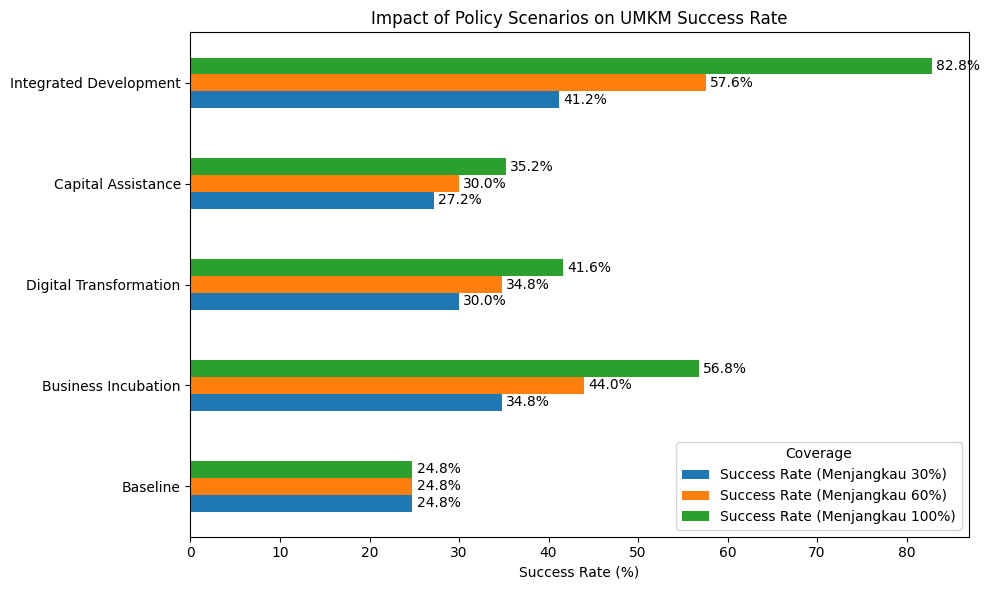

In [ ]:
import matplotlib.pyplot as plt

ax = comparison.set_index('Scenario').plot(
    kind='barh',
    figsize=(10,6)
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        padding=3
    )

plt.xlabel('Success Rate (%)')
plt.ylabel('')
plt.title('Impact of Policy Scenarios on UMKM Success Rate')
plt.legend(title='Coverage')
plt.tight_layout()
plt.show()